## ANALYZING THE INFLUENCE OF VACCINATION COVERAGE ON MEASLES OUTBREAK USING ML TECHNIQUES

The dataset consists of **1,000 records** and **15 features**. These features include:

1. **Region**: Indicates the administrative region. This facilitates regional comparisons in outbreak occurrences and vaccination trends.  
2. **Population**: Represents the total estimated population in the corresponding region. It serves as a reference point for normalizing health indicators such as measles incidence and vaccine coverage.  
3. **Vaccination Coverage**: Denotes the percentage of the population that received the measles vaccine. This is a key determinant in outbreak prediction and herd immunity assessment.  
4. **Healthcare Access**: A categorical variable that rates health service accessibility in the region as “Good,” “Moderate,” or “Poor.” This impacts vaccine delivery and disease surveillance efforts.  
5. **Urban Rural**: Categorizes the region as “Urban” or “Rural.” Urban-rural disparities in healthcare infrastructure and outreach are crucial factors in public health analysis.  
6. **Measles Cases Last Year**: Captures the number of reported measles cases in the preceding year. This is used to assess outbreak trends and support time-series modeling.  
7. **Children Under 5**: Estimates the number of children aged below five years. This population subgroup is most vulnerable to measles and central to vaccination strategies.  
8. **Poverty Rate**: Indicates the percentage of the regional population living below the poverty line. Poverty influences access to healthcare and vaccination compliance.  
9. **Education Level**: Reflects the average educational attainment in the region, classified as “Low,” “Medium,” or “High.” Education is often correlated with public health awareness and vaccine uptake.  
10. **Health Centers Per 100k**: Provides the number of health centers per 100,000 people. This variable reflects the availability of medical infrastructure in the area.  
11. **Media Exposure**: Categorized as “High,” “Medium,” or “Low,” this variable estimates how much access the population has to public health messaging via mass media.  
12. **Migration Rate**: Expressed as a percentage, this variable captures the annual rate of migration in the region. High migration may disrupt vaccination follow-up and increase transmission risks.  
13. **Previous Outbreak**: A binary variable that flags whether the region had a measles outbreak in previous years. This helps identify high-risk areas.  
14. **Month**: Represents the calendar month (1 to 12) associated with the data point. Seasonal variation can influence measles transmission patterns.  
15. **Measles Outbreak**: A binary target variable (0 = No outbreak, 1 = Outbreak) generated based on defined thresholds for vaccination coverage, healthcare access, and recent measles case history. It is the dependent variable used to train and evaluate machine learning models for outbreak prediction.


# Importing the Libraries and Modules to use

In [7]:
import pandas as pd # Import the pandas library for data handling
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np 
import joblib                          # Used to load the trained machine learning model from file

from sklearn.preprocessing import LabelEncoder  # Import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler  # Import standard scaler for optional feature scaling
# Import classification models
from sklearn.ensemble import RandomForestClassifier  # Import Random Forest classifier
from sklearn.svm import SVC                          # Import Support Vector Machine classifier
from xgboost import XGBClassifier                    # Import XGBoost classifier
from sklearn.metrics import accuracy_score, f1_score, classification_report  # To evaluate model performance
from sklearn.model_selection import GridSearchCV     # For hyperparameter tuning
from sklearn.metrics import confusion_matrix



# 1.Loading The Dataset

In [8]:
data=pd.read_csv("measles_data.csv") # Load the measles dataset from a CSV file
data

,Region,Population,Vaccination_Coverage,Healthcare_Access,Urban_Rural,Measles_Cases_Last_Year,Children_Under_5,Poverty_Rate,Education_Level,Health_Centers_Per_100k,Media_Exposure,Migration_Rate,Conflict_Affected,Previous_Outbreak,Month,Measles_Outbreak
0,West,705275,74.91,Poor,Rural,14.0,8928.0,36.57,High,8.76,Medium,2.36,0,1,2.0,1.0
1,Central,833651,77.77,Moderate,Rural,14.0,9836.0,29.99,Low,3.55,High,9.08,0,0,11.0,0.0
2,East,221951,85.96,Good,Urban,12.0,3753.0,57.69,High,7.18,Low,3.09,0,1,4.0,0.0
3,Central,515155,61.42,Poor,Urban,10.0,4282.0,42.11,Low,7.07,High,9.76,0,0,5.0,1.0
4,Central,205716,99.82,Poor,Rural,4.0,7457.0,24.91,Low,2.99,Low,2.81,0,0,12.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,South,38380,91.19,Moderate,Urban,7.0,2724.0,36.49,High,4.51,High,5.48,0,0,10.0,0.0
996,North,644486,97.75,Good,Rural,10.0,2610.0,43.47,Medium,7.67,Medium,1.16,0,1,6.0,0.0
997,North,274500,91.06,Moderate,Rural,7.0,1457.0,51.58,Medium,4.48,High,0.23,1,0,1.0,1.0
998,West,80326,50.08,Poor,Rural,13.0,7646.0,17.52,Low,3.97,Medium,0.51,0,0,11.0,1.0


# 2. EDA(Exploratory Data Analysis)
##  a) Checking the target Balance

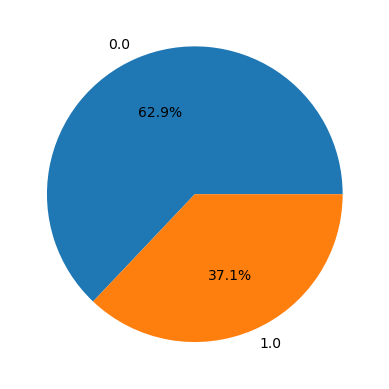

In [9]:
plt.pie(
    data['Measles_Outbreak'].value_counts().values,
    labels=data['Measles_Outbreak'].value_counts().index,
    autopct='%1.1f%%'
)
plt.show()

## b) Data Types
Checking the data types of columns in this data set

In [10]:
# Loop through each column name in the DataFrame 'data'
for col in data.columns: 
    # Print the name of the column and its corresponding data type
    print(f"Column '{col}' has data type: {data[col].dtype}")


Column 'Region' has data type: object
Column 'Population' has data type: int64
Column 'Vaccination_Coverage' has data type: float64
Column 'Healthcare_Access' has data type: object
Column 'Urban_Rural' has data type: object
Column 'Measles_Cases_Last_Year' has data type: float64
Column 'Children_Under_5' has data type: float64
Column 'Poverty_Rate' has data type: float64
Column 'Education_Level' has data type: object
Column 'Health_Centers_Per_100k' has data type: float64
Column 'Media_Exposure' has data type: object
Column 'Migration_Rate' has data type: float64
Column 'Conflict_Affected' has data type: int64
Column 'Previous_Outbreak' has data type: int64
Column 'Month' has data type: float64
Column 'Measles_Outbreak' has data type: float64


## c) A Bar Plot for the Average Vaccination Coverage and Measles Outbreaks

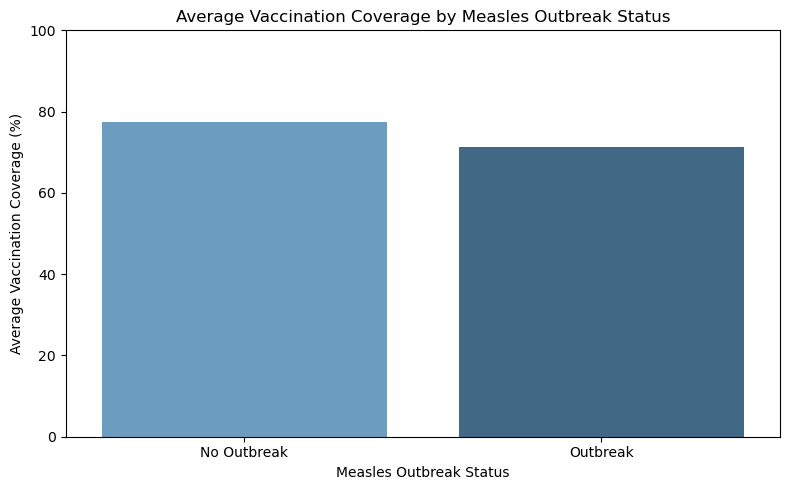

In [11]:
# Group by Measles_Outbreak and compute mean Vaccination_Coverage
avg_coverage = data.groupby('Measles_Outbreak')['Vaccination_Coverage'].mean().reset_index()
avg_coverage['Measles_Outbreak'] = avg_coverage['Measles_Outbreak'].map({0: 'No Outbreak', 1: 'Outbreak'})

# Plot without warning
plt.figure(figsize=(8,5))
sns.barplot(
    data=avg_coverage,
    x='Measles_Outbreak',
    y='Vaccination_Coverage',
    hue='Measles_Outbreak',       # assign hue
    palette='Blues_d',
    legend=False                  # remove unnecessary legend
)

plt.title('Average Vaccination Coverage by Measles Outbreak Status')
plt.ylabel('Average Vaccination Coverage (%)')
plt.xlabel('Measles Outbreak Status')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()



###  Bar Plot: Average Vaccination Coverage vs Measles Outbreak

This bar chart shows the **average vaccination coverage** for regions that experienced a **measles outbreak** versus those that did not:

- Regions **without an outbreak** have a **higher average coverage**.
- Regions **with an outbreak** tend to have **lower average coverage**.

---

###  Conclusion:
> **Lower vaccination coverage** is associated with a **higher likelihood** of measles outbreaks.


## Vaccination Coverage vs Region (Grouped by Outbreak)

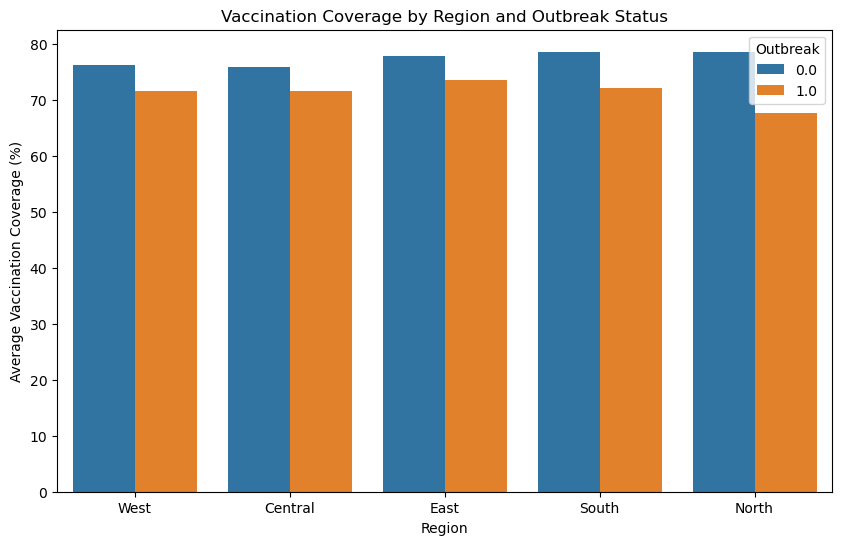

In [12]:
# Vaccination Coverage vs Region (Grouped by Outbreak)
plt.figure(figsize=(10,6)) # Creates a new figure for the plot with a fixed size (10 inches wide, 6 inches tall)
sns.barplot(
    data=data,                      # Uses the dataset already loaded as 'data'
    x="Region",                     # The x-axis represents the regions
    y="Vaccination_Coverage",       # The y-axis shows average vaccination coverage
    hue="Measles_Outbreak",         # Bars are split (colored) based on outbreak status (0 = No, 1 = Yes)
    errorbar=None                   # Removes error bars (so only clean bars are shown)
)
plt.title("Vaccination Coverage by Region and Outbreak Status")
plt.ylabel("Average Vaccination Coverage (%)")
plt.xlabel("Region")
plt.legend(title="Outbreak")
plt.show()


## Interpretation of the Bar Chart

The bar chart illustrates the relationship between vaccination coverage, region, and outbreak status.  
Across all regions, areas without outbreaks consistently record higher vaccination coverage compared to areas with outbreaks.  
This finding underscores the protective effect of vaccination, where higher coverage reduces the likelihood of measles outbreaks.  

Region-specific observations reveal that the **North** exhibits the largest disparity, with outbreak regions having an average coverage of about 68%, while non-outbreak regions reach nearly 79%.  
The **South** and **East** regions also show notable differences, though less pronounced.  
In contrast, the **West** and **Central** regions demonstrate narrower gaps, but outbreaks in these areas are still associated with lower vaccination coverage.  

Overall, the results highlight that regions where vaccination coverage drops below approximately 75% are more susceptible to outbreaks.  
Maintaining coverage levels close to or above 80% is critical for effective measles control and prevention of future outbreaks.  


## Vaccination Coverage vs Measles Cases Last Year (Scatter with Thresholds + Population Bubbles + Quadrant Labels)

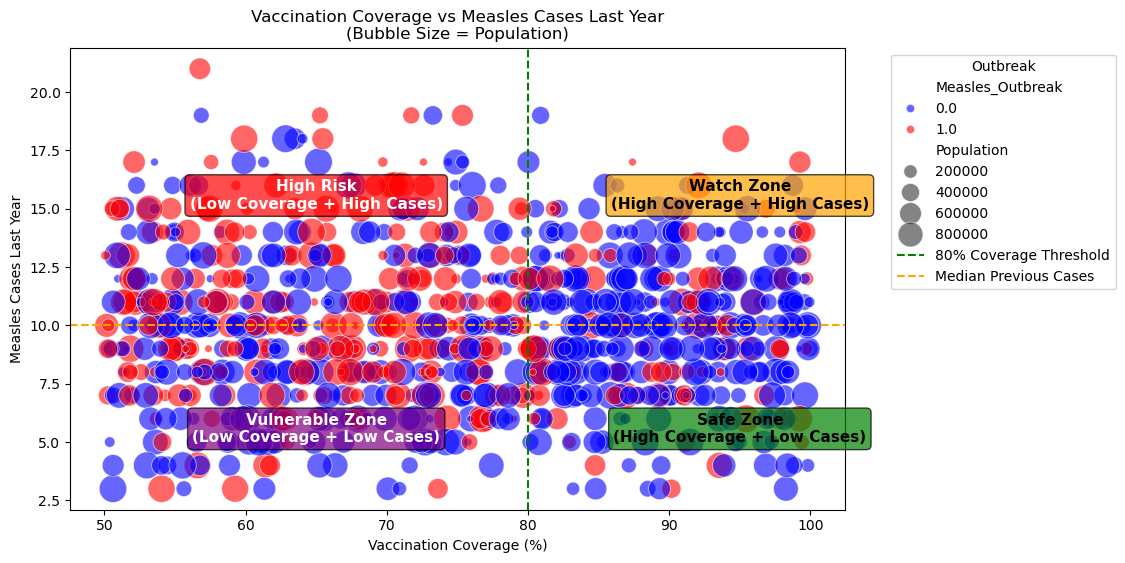

In [13]:
# Scatter plot: Vaccination Coverage vs Measles Cases Last Year
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=data,                            # Uses the dataset named 'data'
    x="Vaccination_Coverage",             # X-axis represents vaccination coverage
    y="Measles_Cases_Last_Year",          # Y-axis represents measles cases reported last year
    size="Population",                    # Bubble size corresponds to population
    sizes=(20, 400),                      # Sets min and max bubble sizes for scaling
    hue="Measles_Outbreak",               # Colors points by outbreak status (0 = No, 1 = Yes)
    palette={0:"blue", 1:"red"},          # Blue = No outbreak, Red = Outbreak
    alpha=0.6                             # Makes bubbles semi-transparent for overlap clarity
)

# Threshold values
coverage_thresh = 80                      # Vaccination coverage threshold (80%) – herd immunity point
cases_thresh = data["Measles_Cases_Last_Year"].median()  
# Median of measles cases last year – divides data into high vs. low past cases

# Add threshold lines
plt.axvline(x=coverage_thresh, color="green", linestyle="--", label="80% Coverage Threshold")  
# Adds vertical dashed line at 80% vaccination coverage
plt.axhline(y=cases_thresh, color="orange", linestyle="--", label="Median Previous Cases")  
# Adds horizontal dashed line at median past measles cases

# Quadrant labels with bold text + background boxes
plt.text(coverage_thresh-15, cases_thresh+5,
         "High Risk\n(Low Coverage + High Cases)",          # Top-left zone: weak vaccination, high past cases
         color="white", fontsize=11, ha="center", weight="bold",
         bbox=dict(facecolor="red", alpha=0.7, boxstyle="round,pad=0.3"))  
# Interpretation: Outbreaks are most likely here (low coverage + high history of cases)

plt.text(coverage_thresh+15, cases_thresh+5,
         "Watch Zone\n(High Coverage + High Cases)",        # Top-right zone: strong vaccination, high past cases
         color="black", fontsize=11, ha="center", weight="bold",
         bbox=dict(facecolor="orange", alpha=0.7, boxstyle="round,pad=0.3"))  
# Interpretation: Outbreaks may still occur here despite high coverage, due to factors like migration or immunity gaps

plt.text(coverage_thresh-15, cases_thresh-5,
         "Vulnerable Zone\n(Low Coverage + Low Cases)",     # Bottom-left zone: weak vaccination, low past cases
         color="white", fontsize=11, ha="center", weight="bold",
         bbox=dict(facecolor="purple", alpha=0.7, boxstyle="round,pad=0.3"))  
# Interpretation: Few cases now, but risky in future because vaccination coverage is too low

plt.text(coverage_thresh+15, cases_thresh-5,
         "Safe Zone\n(High Coverage + Low Cases)",          # Bottom-right zone: strong vaccination, low past cases
         color="black", fontsize=11, ha="center", weight="bold",
         bbox=dict(facecolor="green", alpha=0.7, boxstyle="round,pad=0.3"))  
# Interpretation: Best case scenario – strong herd immunity and few past cases, outbreaks are unlikely

# Labels and title
plt.title("Vaccination Coverage vs Measles Cases Last Year\n(Bubble Size = Population)")  
# Sets the title of the plot
plt.xlabel("Vaccination Coverage (%)")  
# Labels the X-axis
plt.ylabel("Measles Cases Last Year")  
# Labels the Y-axis
plt.legend(title="Outbreak", bbox_to_anchor=(1.05, 1), loc='upper left')  
# Adds a legend for outbreak status (red = outbreak, blue = no outbreak), places it outside the chart
plt.show()  
# Displays the scatter plot

## Interpretation of the Scatter Plot

###  High Risk Zone (Top-Left)
- Low vaccination coverage (<80%) + High measles cases last year (> median).  
- Many outbreaks (red bubbles) appear here.  
- Large bubbles = big populations → very high danger.  

###  Watch Zone (Top-Right)
- High vaccination coverage (≥80%) but still high past cases.  
- Outbreak risk remains due to migration, immunity gaps, or delayed impact.  

###  Vulnerable Zone (Bottom-Left)
- Low vaccination coverage but few past cases.  
- These regions look calm but are **at risk** — a small spark can start an outbreak.  

###  Safe Zone (Bottom-Right)
- High vaccination coverage (≥80%) and low past cases.  
- Outbreaks are rare here.  
- This is the **ideal zone** — shows herd immunity at work.  


# 3. Data Preprocessing 

# a) Missing Values 
Checking and Dealing with the Missing Values

In [14]:
# Check total missing values per column
missing_values = data.isnull().sum()
# Display columns with missing values only
missing_values = missing_values[missing_values > 0]
print("Missing values per column:")
print(missing_values)

Missing values per column:
Vaccination_Coverage        2
Healthcare_Access           1
Urban_Rural                 1
Measles_Cases_Last_Year    13
Children_Under_5            4
Poverty_Rate                3
Migration_Rate              5
Month                       4
Measles_Outbreak            2
dtype: int64


###   Summary of Methods and Reasons for using them to handle Missing values

---

####  Why Use Median for Numerical Columns:
- **Median is robust to outliers**, unlike the mean which can be affected by extreme values.
- Ideal for small amounts of missing data — it's simple, fast, and effective.

---

####  Why Fill Missing Categorical Values with Mode:
- **Mode (most frequent value)** is a logical default when a category is missing.
- Maintains consistency with the existing distribution.
- Works well when only a few values are missing — no need for complex models.

---

####  Why Drop Rows with Missing Target (`Measles_Outbreak`):
- Models require the target variable to be present for **training and evaluation**.
- **Imputing the target** can introduce bias or false labels, leading to poor model performance.


---

In [15]:
# Fill numeric columns with median
numeric_cols = ['Vaccination_Coverage', 'Measles_Cases_Last_Year',     
                'Children_Under_5', 'Poverty_Rate', 'Migration_Rate']    # List of numeric columns with missing values
data[numeric_cols] = data[numeric_cols].fillna(data[numeric_cols].median()) # Fill missing numeric values with column medians

# Fill categorical columns with mode
categorical_cols = ['Urban_Rural', 'Healthcare_Access', 'Month'] # List of categorical columns with missing values
for col in categorical_cols:
   data.loc[:, col] = data[col].fillna(data[col].mode()[0]) # Fill missing categorical values with the most frequent (mode) value


# Drop rows where target 'Measles_Outbreak' is missing
data = data.dropna(subset=['Measles_Outbreak']) 

# To check again the missing values
print("Remaining missing values:")
print(data.isnull().sum())

Remaining missing values:
Region                     0
Population                 0
Vaccination_Coverage       0
Healthcare_Access          0
Urban_Rural                0
Measles_Cases_Last_Year    0
Children_Under_5           0
Poverty_Rate               0
Education_Level            0
Health_Centers_Per_100k    0
Media_Exposure             0
Migration_Rate             0
Conflict_Affected          0
Previous_Outbreak          0
Month                      0
Measles_Outbreak           0
dtype: int64


## b) Checking Outliers
I will use the method of IQR To check the Outliers and Handle them, because it is simple, does not assume a specific data distribution, and is resistant to the effect of extreme values.

In [16]:
# Loop through all numeric columns and check for outliers using IQR
for column in data.select_dtypes(include=['int64', 'float64']).columns:  # Loop through numeric columns only
    Q1 = data[column].quantile(0.25)                                     # Calculate the 25th percentile (Q1) of the column
    Q3 = data[column].quantile(0.75)                                     # Calculate the 75th percentile (Q3) of the column
    IQR = Q3 - Q1                                                        # Compute the Interquartile Range (IQR)
    lower = Q1 - 1.5 * IQR                                               # Define the lower bound for outliers
    upper = Q3 + 1.5 * IQR                                               # Define the upper bound for outliers
    outliers = data[(data[column] < lower) | (data[column] > upper)]     # Identify rows where values are outliers
    print(f"{column}: {len(outliers)} outliers")                          # Print the number of outliers found in the column

Population: 0 outliers
Vaccination_Coverage: 0 outliers
Measles_Cases_Last_Year: 7 outliers
Children_Under_5: 0 outliers
Poverty_Rate: 0 outliers
Health_Centers_Per_100k: 0 outliers
Migration_Rate: 0 outliers
Conflict_Affected: 216 outliers
Previous_Outbreak: 0 outliers
Month: 0 outliers
Measles_Outbreak: 0 outliers


In [17]:
# Columns with outliers to fix
columns_to_fix = [
    'Measles_Cases_Last_Year',      # Numerical column suspected to contain outliers
    'Conflict_Affected',            # Another numerical column to clean
]

# Function to replace outliers in a column with the median
def fix_outliers_with_median(data, column):
    Q1 = data[column].quantile(0.25)          # 25th percentile
    Q3 = data[column].quantile(0.75)          # 75th percentile
    IQR = Q3 - Q1                             # Interquartile range
    lower = Q1 - 1.5 * IQR                    # Lower bound for acceptable values
    upper = Q3 + 1.5 * IQR                    # Upper bound for acceptable values
    median = data[column].median()            # Median value

   # The line replaces outlier values in a column with the median, and data.loc is used to update the entire column safely without warnings.
    data.loc[:, column] = data[column].apply(lambda x: median if x < lower or x > upper else x)

# Apply the outlier-fixing function to each selected column
data = data.copy()  # Important: avoid SettingWithCopyWarning if data is a slice
for col in columns_to_fix:
    fix_outliers_with_median(data, col)

# Re-check for outliers in all numeric columns
for column in data.select_dtypes(include=['int64', 'float64']).columns:  
    Q1 = data[column].quantile(0.25)                                     
    Q3 = data[column].quantile(0.75)                                     
    IQR = Q3 - Q1                                                        
    lower = Q1 - 1.5 * IQR                                              
    upper = Q3 + 1.5 * IQR                                               
    outliers = data[(data[column] < lower) | (data[column] > upper)]     
    print(f"{column}: {len(outliers)} outliers")  

Population: 0 outliers
Vaccination_Coverage: 0 outliers
Measles_Cases_Last_Year: 0 outliers
Children_Under_5: 0 outliers
Poverty_Rate: 0 outliers
Health_Centers_Per_100k: 0 outliers
Migration_Rate: 0 outliers
Conflict_Affected: 0 outliers
Previous_Outbreak: 0 outliers
Month: 0 outliers
Measles_Outbreak: 0 outliers


## c) Resolving Inconsistencies
Checking Formatting inconsistencies and ensured reliable categorical analysis

## c) Feature Transformation
Used Label Encoding to convert categorical columns into numerical format because it is a simple and efficient method for transforming non-numeric labels into integers, making the data suitable for machine learning models that require numerical input.

In [18]:
# Columns to encode
categorical_cols = ['Region', 'Healthcare_Access', 'Urban_Rural', 'Education_Level', 'Media_Exposure']

data = data.copy()

# Create a label encoder object
label_encoders = {}

# Apply label encoding to each column
for col in categorical_cols:
    le = LabelEncoder()
    data.loc[:, col] = le.fit_transform(data[col])  # Safe assignment using .loc[]
    label_encoders[col] = le

data.head()


,Region,Population,Vaccination_Coverage,Healthcare_Access,Urban_Rural,Measles_Cases_Last_Year,Children_Under_5,Poverty_Rate,Education_Level,Health_Centers_Per_100k,Media_Exposure,Migration_Rate,Conflict_Affected,Previous_Outbreak,Month,Measles_Outbreak
0,4,705275,74.91,2,0,14.0,8928.0,36.57,0,8.76,2,2.36,0,1,2.0,1.0
1,0,833651,77.77,1,0,14.0,9836.0,29.99,1,3.55,0,9.08,0,0,11.0,0.0
2,1,221951,85.96,0,1,12.0,3753.0,57.69,0,7.18,1,3.09,0,1,4.0,0.0
3,0,515155,61.42,2,1,10.0,4282.0,42.11,1,7.07,0,9.76,0,0,5.0,1.0
4,0,205716,99.82,2,0,4.0,7457.0,24.91,1,2.99,1,2.81,0,0,12.0,0.0


In [19]:
# Columns to convert to integer
columns_to_convert = [
    'Children_Under_5',
    'Health_Centers_Per_100k',
    'Month',
    'Measles_Outbreak','Measles_Cases_Last_Year'
]

# Convert each column to int
for col in columns_to_convert:
    data[col] = data[col].astype(int)
data

,Region,Population,Vaccination_Coverage,Healthcare_Access,Urban_Rural,Measles_Cases_Last_Year,Children_Under_5,Poverty_Rate,Education_Level,Health_Centers_Per_100k,Media_Exposure,Migration_Rate,Conflict_Affected,Previous_Outbreak,Month,Measles_Outbreak
0,4,705275,74.91,2,0,14,8928,36.57,0,8,2,2.36,0,1,2,1
1,0,833651,77.77,1,0,14,9836,29.99,1,3,0,9.08,0,0,11,0
2,1,221951,85.96,0,1,12,3753,57.69,0,7,1,3.09,0,1,4,0
3,0,515155,61.42,2,1,10,4282,42.11,1,7,0,9.76,0,0,5,1
4,0,205716,99.82,2,0,4,7457,24.91,1,2,1,2.81,0,0,12,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,3,38380,91.19,1,1,7,2724,36.49,0,4,0,5.48,0,0,10,0
996,2,644486,97.75,0,0,10,2610,43.47,2,7,2,1.16,0,1,6,0
997,2,274500,91.06,1,0,7,1457,51.58,2,4,0,0.23,0,0,1,1
998,4,80326,50.08,2,0,13,7646,17.52,1,3,2,0.51,0,0,11,1


# 4. Train-Test Split
To split the dataset into two parts: 80% for training the machine learning models and
 20% for testing them.

In [20]:
# Define your features (X) and target variable (y)
X = data.drop(columns=['Measles_Outbreak'])  # Replace with your actual target column
y = data['Measles_Outbreak']

scaler = StandardScaler()  # Initialize the scaler
X_scaled = scaler.fit_transform(X)  # Scale features to have zero mean and unit variance

# Split the dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, stratify=y, random_state=42)

# Output dataset shapes
print(f"Training samples: {X_train.shape[0]}, Testing samples: {X_test.shape[0]}")


Training samples: 798, Testing samples: 200


# 5. Multicollinearity among features

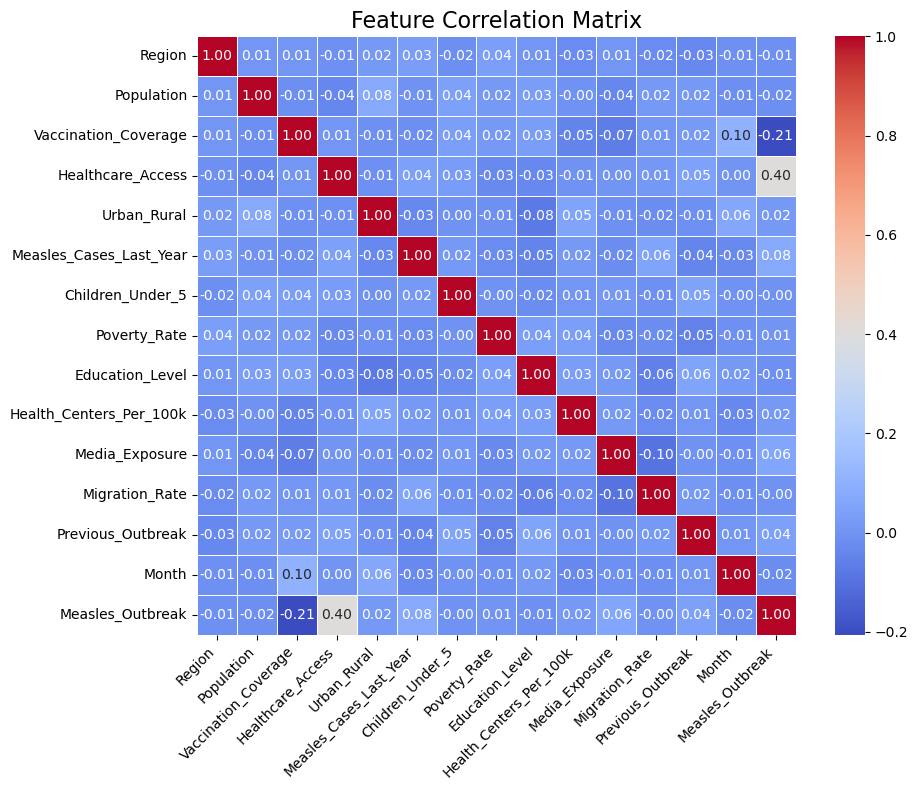

In [41]:
# Compute the correlation matrix
corr_matrix = data.corr()         # Calculate correlation coefficients between all numeric columns

# Plot the heatmap
plt.figure(figsize=(10, 8))       # Set the size of the plot
sns.heatmap(
    corr_matrix,                  # Use the correlation matrix as input
    annot=True,                   # Show correlation coefficient values inside the heatmap cells
    cmap='coolwarm',              # Use a diverging color map: cool = negative, warm = positive
    fmt=".2f",                    # Format the numbers to 2 decimal places
    linewidths=0.5,               # Add lines between the cells
    square=True                   # Force each cell to be square
)

plt.title("Feature Correlation Matrix", fontsize=16)      # Add a title to the heatmap
plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels for better readability
plt.tight_layout()                   # Automatically adjust spacing to prevent label overlap
plt.show()                           # Display the heatmap


## Healthcare_Access: 
0.40 — A moderately positive correlation, meaning better healthcare access is somewhat associated with measles outbreaks (this  means areas with access report more reliably).

## Vaccination_Coverage:
-0.21 — A weak negative correlation, suggesting that higher vaccination coverage slightly reduces the chance of an outbreak (which aligns with expectations).

# 6. Training and  Model Evaluation

In [32]:
# 1. Random Forest 
print(" Random Forest Classifier ")  # Display model name

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)  # Create a Random Forest model with 100 trees
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)  # Make predictions on the test set

rf_acc = accuracy_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)

print(f"Accuracy: {accuracy_score(y_test, rf_pred):.2f}")  # Print accuracy of the model (how many predictions were correct)
print("Classification Report:")  # Display label
print(classification_report(y_test, rf_pred))  # Print precision, recall, F1-score, and support for each class

# 2. Support Vector Machine 
print("\n Support Vector Machine (SVM) ")  # Display model name

svm_model = SVC(kernel='linear', C=1.0)  # Create an SVM model using a linear kernel and regularization parameter C=1.0
svm_model.fit(X_train, y_train)  # Train the SVM model on training data

svm_acc = accuracy_score(y_test, svm_pred)
svm_f1 = f1_score(y_test, svm_pred)

svm_pred = svm_model.predict(X_test)  # Make predictions on the test set

print(f"Accuracy: {accuracy_score(y_test, svm_pred):.2f}")  # Print the accuracy of the SVM model
print("Classification Report:")  # Display label
print(classification_report(y_test, svm_pred))  # Print the full classification report for SVM

# 3. XGBoost 
print("\n XGBoost Classifier ")  # Display model name

xgb_model = XGBClassifier(eval_metric='logloss')  # Create an XGBoost model with 'logloss' as the evaluation metric
xgb_model.fit(X_train, y_train)  # Train the XGBoost model on training data

xgb_acc = accuracy_score(y_test, xgb_pred)
xgb_f1 = f1_score(y_test, xgb_pred)

xgb_pred = xgb_model.predict(X_test)  # Make predictions on the test set

print(f"Accuracy: {accuracy_score(y_test, xgb_pred):.2f}")  # Print the accuracy of the XGBoost model
print("Classification Report:")  # Display label
print(classification_report(y_test, xgb_pred))  # Print the classification report for XGBoost

# --- Results Table ---
results = pd.DataFrame({                     # Create a DataFrame to hold model results
    "Model": ["Random Forest", "Support Vector Machine", "XGBoost"],   # Column with model names
    "Accuracy": [rf_acc, svm_acc, xgb_acc],   # Column with accuracy scores for each model
    "F1 Score": [rf_f1, svm_f1, xgb_f1]       # Column with F1-scores for each model
})

print("\nModel Performance Summary:")        # Print a title before showing the table
print(results.to_string(index=False))        # Print the table without row index numbers


 Random Forest Classifier 
Accuracy: 0.80
Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.98      0.86       126
           1       0.95      0.49      0.64        74

    accuracy                           0.80       200
   macro avg       0.86      0.74      0.75       200
weighted avg       0.83      0.80      0.78       200


 Support Vector Machine (SVM) 
Accuracy: 0.72
Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.82      0.79       126
           1       0.64      0.55      0.59        74

    accuracy                           0.72       200
   macro avg       0.70      0.69      0.69       200
weighted avg       0.71      0.72      0.72       200


 XGBoost Classifier 
Accuracy: 0.77
Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.93      0.83       126
           1       0.80      0.49      0.6

# 7.  HyperParameter Tuning
##  What is Hyperparameter Tuning?

Is the process of selecting the best set of values for the parameters that control the learning process of a machine learning model. Unlike model parameters (which are learned from data), **hyperparameters are set before training** and have a significant impact on the model's performance. Proper tuning helps avoid overfitting or underfitting, improves accuracy, and ensures that the model generalizes well to unseen data.

---

##  Summary Table: Importance of Hyperparameter Tuning

| **Model**        | **Why Hyperparameter Tuning is Important**                                                                 |
|------------------|------------------------------------------------------------------------------------------------------------|
| **SVM**          | To balance margin and misclassification, choose the right kernel, and avoid overfitting or underfitting.   |
| **Random Forest**| To control model complexity, prevent overfitting, and optimize both speed and predictive accuracy.          |
| **XGBoost**      | To boost accuracy, prevent overfitting using regularization, and improve training efficiency.               |


In [21]:
from tabulate import tabulate   #  for pretty table output
#  1. Random Forest with GridSearch 
print(" Random Forest Classifier with Hyperparameter Tuning")

# Define the parameter grid to search
rf_params = {
    'n_estimators': [50, 100, 200, 300],         # Number of trees in the forest
    'max_depth': [None, 10, 20, 30],        # Maximum depth of the tree
    'min_samples_split': [2, 5,10]         # Minimum number of samples to split an internal node
}

# Create the base Random Forest model
rf = RandomForestClassifier(random_state=42)

# Perform grid search using 5-fold cross-validation
rf_grid = GridSearchCV(rf, rf_params, cv=5, scoring='accuracy', n_jobs=-1)

# Train the model with the best parameters
rf_grid.fit(X_train, y_train)

# Make predictions using the best estimator found
rf_pred = rf_grid.predict(X_test)

# Evaluate the tuned model
print(f"Best Parameters: {rf_grid.best_params_}")
print(f"Accuracy: {accuracy_score(y_test, rf_pred):.2f}")
print("Classification Report:")
print(classification_report(y_test, rf_pred))


#  2. Support Vector Machine with GridSearch 
print("\n Support Vector Machine (SVM) with Hyperparameter Tuning")

# Define the parameter grid for SVM
svm_params = {
    'C': [0.1, 1, 10, 100,],           # Regularization parameter
    'kernel': ['linear', 'rbf', 'poly'],# Kernel type: linear or radial basis function or Polynomial
    'gamma': ['scale', 'auto']  # Kernel coefficient
}

# Create the base SVM model
svm = SVC()

# Perform grid search with cross-validation
svm_grid = GridSearchCV(svm, svm_params, cv=5, scoring='accuracy', n_jobs=-1)
svm_grid.fit(X_train, y_train)  # Train with different hyperparameter combinations

# Predict using the best model
svm_pred = svm_grid.predict(X_test)

# Evaluate
print(f"Best Parameters: {svm_grid.best_params_}")
print(f"Accuracy: {accuracy_score(y_test, svm_pred):.2f}")
print("Classification Report:")
print(classification_report(y_test, svm_pred))


# 3. XGBoost with GridSearch 
print("\n XGBoost Classifier with Hyperparameter Tuning")

# Define the parameter grid for XGBoost
xgb_params = {
    'n_estimators': [50 ,100, 200, 300],      # Number of boosting rounds
    'max_depth': [3, 6, 10],         # Maximum depth of trees
    'learning_rate': [0.01, 0.1, 1],    # Step size shrinkage
    'subsample': [0.8, 1.0]          # % of samples used per tree
}

# Create the base XGBoost model
xgb = XGBClassifier(eval_metric='logloss')

# Perform grid search
xgb_grid = GridSearchCV(xgb, xgb_params, cv=5, scoring='accuracy', n_jobs=-1)
xgb_grid.fit(X_train, y_train)  # Train with grid search

# Predict with best model
xgb_pred = xgb_grid.predict(X_test)

# Evaluate
print(f"Best Parameters: {xgb_grid.best_params_}")
print(f"Accuracy: {accuracy_score(y_test, xgb_pred):.2f}")
print("Classification Report:")
print(classification_report(y_test, xgb_pred))



 Random Forest Classifier with Hyperparameter Tuning
Best Parameters: {'max_depth': 10, 'min_samples_split': 10, 'n_estimators': 200}
Accuracy: 0.80
Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.98      0.86       126
           1       0.92      0.49      0.64        74

    accuracy                           0.80       200
   macro avg       0.84      0.73      0.75       200
weighted avg       0.82      0.80      0.78       200


 Support Vector Machine (SVM) with Hyperparameter Tuning
Best Parameters: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
Accuracy: 0.78
Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.94      0.84       126
           1       0.82      0.50      0.62        74

    accuracy                           0.78       200
   macro avg       0.79      0.72      0.73       200
weighted avg       0.78      0.78      0.76       200


 XGBoost Classif

## Comparing The Model Accuracy and F1-Score and Visualizing


=== Model Performance Comparison ===
Random Forest: Accuracy = 0.80, F1-score = 0.64
SVM: Accuracy = 0.78, F1-score = 0.62
XGBoost: Accuracy = 0.81, F1-score = 0.65

 Best Model Based on Accuracy & F1-score: XGBoost


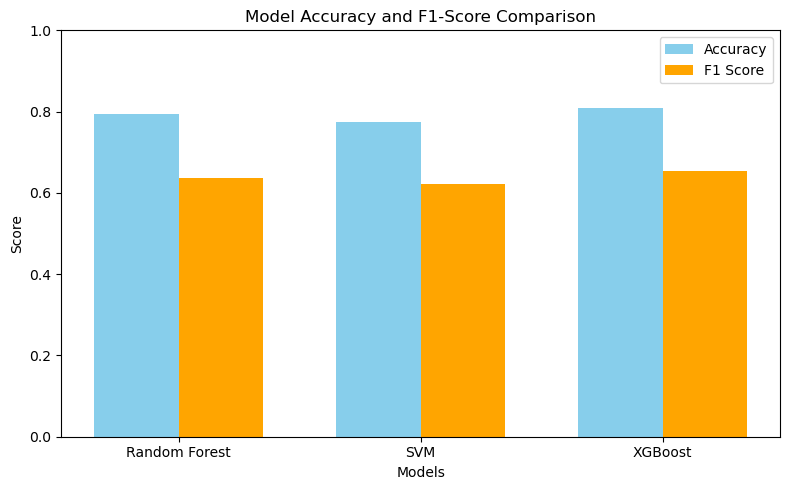

In [36]:
#  Store model performance scores 
model_scores = {
    'Random Forest': {
        'Accuracy': accuracy_score(y_test, rf_pred),     # Calculate accuracy for Random Forest
        'F1': f1_score(y_test, rf_pred)                   # Calculate F1-score for Random Forest
    },
    'SVM': {
        'Accuracy': accuracy_score(y_test, svm_pred),     # Accuracy for SVM
        'F1': f1_score(y_test, svm_pred)                   # F1-score for SVM
    },
    'XGBoost': {
        'Accuracy': accuracy_score(y_test, xgb_pred),     # Accuracy for XGBoost
        'F1': f1_score(y_test, xgb_pred)                   # F1-score for XGBoost
    }
}

#  Print the comparison 
print("\n=== Model Performance Comparison ===")
for model, scores in model_scores.items():
    print(f"{model}: Accuracy = {scores['Accuracy']:.2f}, F1-score = {scores['F1']:.2f}")

#  Identify the best model based on F1-score 
best_model = max(model_scores, key=lambda k: model_scores[k]['F1'])  # Find model with highest F1-score
print(f"\n Best Model Based on Accuracy & F1-score: {best_model}")  # Display best model

#  Visualization 
# Extract names, accuracies, and F1-scores
models = list(model_scores.keys())
accuracies = [model_scores[m]['Accuracy'] for m in models]
f1_scores = [model_scores[m]['F1'] for m in models]

# Set bar positions
x = range(len(models))
width = 0.35

# Plot
plt.figure(figsize=(8, 5))
plt.bar(x, accuracies, width=width, label='Accuracy', color='skyblue')
plt.bar([i + width for i in x], f1_scores, width=width, label='F1 Score', color='orange')

# Customize plot
plt.xlabel('Models')
plt.ylabel('Score')
plt.title('Model Accuracy and F1-Score Comparison')
plt.xticks([i + width / 2 for i in x], models)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()

# Show plot
plt.show()


In [37]:
import joblib                          # Used to load the trained machine learning model from file
joblib.dump(xgb_grid.best_estimator_, "best_model.pkl")  # Save to file

['best_model.pkl']

# Using XGBoost to predict using the best Parameters

In [38]:
# Define the model with best parameters
xgb_model = XGBClassifier(
    learning_rate=0.01,
    max_depth=3,
    n_estimators=50,
    subsample=0.8,
    eval_metric='logloss',  # to suppress warning
    random_state=42
)

# Train the model
xgb_model.fit(X_train, y_train)

# Predict on test set
y_pred = xgb_model.predict(X_test)

# Evaluate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Classification Report:")
print(classification_report(y_test, xgb_pred))
#print(f"Accuracy: {accuracy * 100:.2f}%")

# Predict only the first 5 rows
y_pred = xgb_model.predict(X_test[:5])
y_actual = y_test[:5]

# Combine predicted and actual values into a DataFrame for comparison
comparison_data = pd.DataFrame({
    'Actual': y_actual,
    'Predicted': y_pred
})

# Display the first 5 results
print("First 5 Predictions vs Actual:")
print(comparison_data)

Classification Report:
              precision    recall  f1-score   support

           0       0.77      1.00      0.87       126
           1       1.00      0.49      0.65        74

    accuracy                           0.81       200
   macro avg       0.88      0.74      0.76       200
weighted avg       0.85      0.81      0.79       200

First 5 Predictions vs Actual:
     Actual  Predicted
791       0          0
912       0          0
751       1          1
260       0          0
855       0          0


## Confusion Matrix

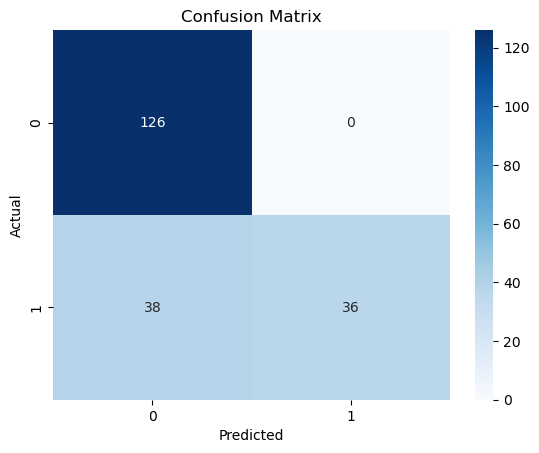

In [39]:
y_pred = xgb_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

True Negatives (TN = 126): Model correctly predicted class 0 when the actual class was 0.

False Positives (FP = 0): Model incorrectly predicted class 1 when the actual class was 0.

False Negatives (FN = 38): Model incorrectly predicted class 0 when the actual class was 1.

True Positives (TP = 36): Model correctly predicted class 1 when the actual class was 1.